In [20]:
import networkx as nx

import numpy as np
import matplotlib.pyplot as plt
import math
from math import comb, factorial
from itertools import combinations
from functools import partial

import matplotlib.pyplot as plt


from typing import Union

from tabulate import tabulate
import pandas as pd

from scipy.linalg import sqrtm,eig


import perceval as pcvl
import exqalibur as xqlbr

import perceval as pcvl

from BSutils import *
from scipy.stats import unitary_group

from itertools import permutations
from scipy.special import factorial
import vegas

Theorem 2 from Changhun Oh paper

In [21]:
# ADD PERMANENT CALCULATION
def permanent(A, in_state, out_state=None):
	if(not out_state):
		out_state=in_state
	# print(A)
	# submatrix = A[:,np.where(in_state)[0]]
	# submatrix = submatrix[np.where(out_state)[0],:]
	# print(submatrix)
	# print(A)
	
	A = A.T
	modes= len(in_state)
	photons = sum(in_state)
	submatrix = np.concatenate([np.tile(A[i,:],in_state[i]).reshape((in_state[i],modes)) for i in np.where(in_state)[0] ])
	submatrix = np.concatenate([np.tile(submatrix[:,i],out_state[i]).reshape((out_state[i],photons)) for i in np.where(out_state)[0]])
	# print(submatrix)
	return xqlbr.permanent_cx(submatrix, ptype="ryser")


def DickeState(modes: int,photons: int) -> tuple:
    """Return a Dicke state with given number of modes & photons
        A Dicke state D(m,n)) is defined as the coherent superposition of Fock states with n unbunched photons within m modes.
        (he superposition if composd of n choose m Fock states)
    Args:
        modes (int): number of modes
        photons (int): number of photons

    Returns:
       (pcvl.StateVector, list): Dicke state along with the corresponding list of Focj states
    """
    if(photons > modes):
        print("Fallback to case photons = modes")
        photons=modes

    dickebasis = list(set(permutations([1]*photons+[0]*(modes-photons))))
    dicke_state_pcvl=pcvl.StateVector(dickebasis[0])
    for d in dickebasis[1:]:
        dicke_state_pcvl+= pcvl.StateVector(d)
    return dicke_state_pcvl,dickebasis



def compute_simbackend_amplitudes(self,unitary, instate, outstate):
        # Fastest
        U = pcvl.Unitary(pcvl.Matrix(unitary))
        simulator = pcvl.Simulator(pcvl.SLOSBackend())
        simulator.set_circuit(U)

        res = 0
        for el in outstate:
            ramp = 0
            # print(self.instate)
            for i,coeff in instate:
                ramp += simulator.prob_amplitude(i,el)*coeff
            res += np.abs(ramp)**2
        
        return res



def expectation_value_permanent(U,in_state,out_state=None):
	if(not out_state):
		out_state=in_state
	return (permanent(U,in_state, out_state=out_state))/np.sqrt(np.prod(factorial(in_state))*np.prod(factorial(out_state)))


def coherent_state(alpha,cherrypick=None,photon_cut=2):
	alpha = np.asarray(alpha)
	if not cherrypick:
		cherrypick=range(photon_cut)
	# if(cherrypick):
	# 	return np.array(zip(cherrypick, )))
	return np.array([np.exp(-np.abs(alpha)**2/2)*alpha**n /np.sqrt(factorial(n)) 
		    for n in cherrypick], dtype=complex).T.swapaxes(0,1)
	#shape (alpha.shape[0], mode, photon_cut/cherrypick)

# def state_repr(state,photon_cut=2):
# 	modes = len(state)
# 	res =  np.zeros((modes,photon_cut))
# 	for i in range(modes):
# 		res[i,state[i]] = 1
# 	#shape (mode, photon_cut)
# 	return res



# def q_distr(alpha, state_in, cherrypick=False,photon_cut=2):
# 	alpha = np.asarray(alpha)
# 	if(len(alpha.shape)==0):
# 		alpha = alpha.reshape(1,1)
# 	elif(len(alpha.shape)==1):
# 		alpha=alpha.reshape(alpha.shape[0],1)
# 	modes = len(state_in)
# 	if not cherrypick:
# 	# Full calculation
# 		coherent_alpha = coherent_state(alpha,photon_cut=photon_cut)
# 		# print( (np.abs(np.tensordot(coherent_alpha.conj(), state_in, axes=([2,1])))**2).shape)
# 		M = np.abs(np.tensordot(coherent_alpha.conj(), state_in, axes=([2,1])))**2
# 		q = np.prod(np.diagonal(M, axis1=1, axis2=2), axis=1)
# 		return 1/(np.pi**modes)* q
# 	else:
# 		# state_in array [modes,[(num_photon,amplitude)]]
# 		q_cumul = 1
# 		for i in range(modes):
# 			num_photons_pick,amplitudes = zip(*state_in[i])
# 			coherent_alpha = coherent_state(alpha[:,i],cherrypick=num_photons_pick).T
# 			# print("coherent", coherent_alpha)
# 			# print("amplitudes",amplitudes)
# 			q = np.abs(coherent_alpha.conj()@np.array(amplitudes))**2
# 			q_cumul*=q
# 		return 1/(np.pi**modes)* q_cumul

def q_pdf(alpha, state_in):
	# modes = np.asarray(state_in).shape[0]
	# q_modes = np.ones(modes)
	alpha = np.asarray(alpha)
	if(len(alpha.shape)==0):
		alpha = alpha.reshape(1,1)
	elif(len(alpha.shape)==1):
		alpha=alpha.reshape(alpha.shape[0],1)
		
	q_modes=[]
	for i,s in enumerate(state_in):
		num_photons = np.array([ a[0] for a in s],dtype=int)
		amplitudes = np.array([ a[1] for a in s])

		coherent_factor = np.tile(np.exp(-np.abs(alpha[:,i])**2/2),len(num_photons)).reshape(len(num_photons),alpha.shape[0]).T \
								* (np.tile(alpha[:,i],len(num_photons)).reshape(len(num_photons),alpha.shape[0]).T **num_photons )/np.sqrt(factorial(num_photons))
		coherent_factor=coherent_factor.conj()

		scalarprod =  coherent_factor @ amplitudes
		
		q_modes.append(np.abs(scalarprod)**2/np.pi )
	# np.exp(-np.abs(alpha)**2/2)/np.pi * sum(
	return np.prod(q_modes,axis=0)




def X_pdf(alpha,state_in,state_out,unitary):
	alpha = np.asarray(alpha)
	if(len(alpha.shape)==0):
		alpha = alpha.reshape(1,1)
	elif(len(alpha.shape)==1):
		alpha=alpha.reshape(alpha.shape[0],1)

	evolved_alpha = np.einsum('ij,lj->li', unitary, alpha)

	q_modes=[]
	for i,(s,so) in enumerate(list(zip(state_in,state_out))):
		num_photons = np.array([ a[0] for a in s],dtype=int)
		amplitudes = np.array([ a[1] for a in s])

		num_photons_out = np.array([ a[0] for a in so],dtype=int)
		amplitudes_out = np.array([ a[1] for a in so])

		coherent_factor = np.tile(np.exp(-np.abs(alpha[:,i])**2/2),len(num_photons)).reshape(len(num_photons),alpha.shape[0]).T \
								* (np.tile(alpha[:,i],len(num_photons)).reshape(len(num_photons),alpha.shape[0]).T **num_photons )/np.sqrt(factorial(num_photons))
		coherent_factor=coherent_factor.conj()

		evolved_coherent_factor = np.tile(np.exp(-np.abs(evolved_alpha[:,i])**2/2),len(num_photons_out)).reshape(len(num_photons_out),evolved_alpha.shape[0]).T \
								* (np.tile(evolved_alpha[:,i],len(num_photons_out)).reshape(len(num_photons_out),evolved_alpha.shape[0]).T **num_photons_out )/np.sqrt(factorial(num_photons_out))
		
		num = evolved_coherent_factor @ amplitudes_out.conj()
		# print(coherent_factor.shape,amplitudes.shape)
	
		denom = (coherent_factor @ amplitudes).conj()
		# print(num.shape,denom.shape)
		q_modes.append(num/denom)
	# 	print("lol")
	# 	print(num,denom)
	# 	print("lol2", (num/denom))
	# print("lol3",q_modes)
	return np.prod(q_modes,axis=0)

def sample_qmode(state_in,size=1000, method='cumulative'):
	if(method=='cumulative'):	
		x = np.linspace(0,5,100*size+1)
		jac = np.abs(x)
		cumulative = np.cumsum(q_pdf(x.reshape((100*size+1,1)),state_in)*jac*2*np.pi)/(100*size)
		a = np.random.uniform(0,cumulative[-1],size)
		# print(cumulative[-1])
		res = np.searchsorted(cumulative,a )
		return x[res],np.random.uniform(0,2*np.pi,size=size)
		

def approx(state_in,state_out,unitary,size=1000):
	cumul=1
	alphas = np.zeros((size,len(state_in)),dtype=complex)

	for i,s in enumerate(state_in):
		s = np.array([s])
		# samples_alpha,wgts = sample_qmode(sv,size=size)
		samples_alpha,phases = sample_qmode(s,size=size)
		alphas[:,i] = samples_alpha*np.exp(1.j*phases)

	
	return np.average(X_pdf(alphas,state_in,state_out,unitary))

	# for s,so in list(zip(state_in,state_out)):
	# 	s = np.array([s])
	# 	so = np.array([so])
	# 	res = X_pdf(alphas,s,so,unitary)
	# 	cumul*=res
	
	# return np.average(cumul)


# def X_distr(alpha, Unitary, state_in, state_out, cherrypick=False, photon_cut=2 ):
# 	modes = len(state_in)
# 	if not cherrypick:
# 		coherent_alpha = coherent_state(alpha,photon_cut)
# 		# print("lol")
# 		# print(Unitary.shape,alpha.shape)

# 		# print(np.tensordot(alpha,Unitary, axes=([1,1])).shape)
# 		evolved_coherent_state = coherent_state(np.tensordot(alpha,Unitary, axes=([1,1])),photon_cut)

# 		# print(evolved_coherent_state.shape)
# 		# print(state_out.shape)
# 		# num = np.array([ np.vecdot(o_state,m_state) for o_state,m_state in zip(state_out,evolved_coherent_state)])

# 		num = np.tensordot(evolved_coherent_state,state_out.conj(), axes=([2,1]))
# 		# print(num.shape)
# 		denom = np.tensordot(coherent_alpha.conj(), state_in, axes=([2,1])).conj()
# 	# print(denom.shape)
				
# 		return np.prod(np.diagonal(num/denom, axis1=1, axis2=2), axis=1)
	
# 	#	return np.einsum(num/denom,[0,1,1])

# 	else:
# 		return -1
	# 	X_cumul = 1
	# 	for i in range(modes):
	# 		num_photons_pick,amplitudes = zip(*state_in[i])
	# 		coherent_alpha = coherent_state(alpha[:,i],cherrypick=num_photons_pick).T
	# 		# print("coherent", coherent_alpha)
	# 		# print("amplitudes",amplitudes)
	# 		q = np.abs(coherent_alpha.conj()@np.array(amplitudes))


### 1 mode

In [22]:
print(np.abs(approx([[(2,1)]],[[(2,1)]],np.array([[np.exp(1.j*np.random.uniform(0,2*np.pi))]])))**2)
print(np.abs(approx([[(2,1)]],[[(2,1)]],np.array([[np.exp(1.j*np.random.uniform(0,2*np.pi))]])))**2)

1.0
0.9999999999999996


### 2 modes

In [23]:
modes = 2
# unitary = unitary_group.rvs(modes)
unitary=1/np.sqrt(2)*np.array([[1,1],[1,-1]],dtype=complex)
# unitary = np.array([[1]])
s = [1,1]#,2,1,0,1,1,0,1,1,0]
state = np.array([[(1,1)],[(1,1)]])#np.array([(tuple(zip([2,0],np.ones(modes))))])

so=[2,0]
# state_o = np.array([(tuple(zip([1,1],np.ones(modes))))])
state_o = [[(2,1)],[(0,1)]]

print(" exact", np.abs((expectation_value_permanent(unitary,s,so)))**2)
print()
for _ in range(10):
	print((np.abs(approx(state,state_o,unitary,size=10000)))**2)

 exact 0.4999999999999996

0.4924007774564868
0.4963767367555302
0.5108409141756952
0.5030150424116718
0.5060748428023762
0.499339260197707
0.4918918271141895
0.48914138424292214
0.4984421017584101
0.4962389091589063


In [24]:
modes = 2
unitary = unitary_group.rvs(modes)
# unitary=1/np.sqrt(2)*np.array([[1,1],[1,-1]],dtype=complex)
# unitary = np.array([[1]])
s = [1,1]#,2,1,0,1,1,0,1,1,0]
state = np.array([[(1,1)],[(1,1)]])#np.array([(tuple(zip([2,0],np.ones(modes))))])

so=[2,0]
# state_o = np.array([(tuple(zip([1,1],np.ones(modes))))])
state_o = [[(2,1)],[(0,1)]]

print(" exact", np.abs((expectation_value_permanent(unitary,s,so)))**2)
print()
for _ in range(10):
	print((np.abs(approx(state,state_o,unitary,size=1000)))**2)

 exact 0.4391029818110458

0.4806141862068842
0.39896129070022945
0.4569826148739863
0.39467711281336215
0.47281929461040406
0.4420972949011518
0.4562771022294644
0.3894788966931803
0.4309587735857144
0.4635748991234731


### 3 modes

In [25]:
modes = 3
unitary = unitary_group.rvs(modes)

s = [1,1,1]#,2,1,0,1,1,0,1,1,0]
state = np.array([[(1,1)],[(1,1)],[(1,1)]])#np.array([(tuple(zip([2,0],np.ones(modes))))])

so=[0,3,0]
# state_o = np.array([(tuple(zip([1,1],np.ones(modes))))])
state_o = [[(0,1)],[(3,1)],[(0,1)]]

print(" exact", np.abs((expectation_value_permanent(unitary,s,so)))**2)
print()
for _ in range(10):
	print((np.abs(approx(state,state_o,unitary,size=100000)))**2)

 exact 0.0789436617997891

0.07925399106416829
0.0784893417397888
0.07878167728330948
0.07909867555574218
0.07936189423590644
0.07886270929081605
0.08113706222624398
0.0778476052924444
0.07620474128197423
0.07905100018632412


In [26]:
np.abs((expectation_value_permanent(unitary,s,so)))**2

0.0789436617997891

In [27]:
from perceval.algorithm import Sampler  # import the Sampler class

p = pcvl.Processor("SLOS", pcvl.Unitary(pcvl.Matrix(unitary)))
p.with_input(pcvl.BasicState([1,1,1]))
sampler = pcvl.algorithm.Sampler(p)
sample_count = sampler.probs()
print(sample_count['results'])

{
	|0,0,3>: 0.14994561098137518
	|0,3,0>: 0.07894366179978907
	|1,1,1>: 0.1320161790547113
	|1,0,2>: 0.06002660916837225
	|2,1,0>: 0.17542282058389522
	|1,2,0>: 0.08438971604734788
	|0,2,1>: 0.11316399564853834
	|2,0,1>: 0.06368459087537302
	|0,1,2>: 0.060622591570253646
	|3,0,0>: 0.08178422427034408
}


### SBS

In [28]:
unitary = np.array([[np.exp(1.j*np.random.uniform(0,2*np.pi))]])
# print("exact", np.abs(superposition_perm(unitary,[1])[0])**2)
print(np.abs(expectation_value_permanent(unitary,[2],[2]))**2)



print(np.abs(approx([[(0,0),(2,1)]],[[(2,1)]],unitary))**2)

print(np.abs(approx([[(0,1)]],[[(2,1)]],unitary))**2)
print(np.abs(approx([[(2,1)]],[[(2,1)]],unitary))**2)
# print(np.abs(approx([[(2,1)]],[[(2,1)]],unitary))**2)

1.0
0.9999999999999998
0.0016726492090787897
0.9999999999999998


In [29]:
print(np.abs(approx([[(2,1)]],[[(2,1)]],unitary))**2)

0.9999999999999998


In [30]:
print(np.abs(expectation_value_permanent(unitary,[2],[2]))**2)
print(np.abs(approx([[(2,1)]],[[(2,1)]],unitary) )**2)

print(np.abs(approx([[(0,1), (2,1)]],[[(2,1)]],unitary))**2)
print()
print(approx([[(0,1/np.sqrt(2)), (2,1/np.sqrt(2))]],[[(2,1)]],unitary))
print(1/2*approx([[(2,1)]],[[(2,1)]],unitary) )


1.0
0.9999999999999998
0.27079272261396586

(0.03466759430977164+0.7652743791669063j)
(0.027173026774201296+0.49926108061406965j)


In [31]:
print(1/2*expectation_value_permanent(unitary,[2],[2]))# + 1/2*expectation_value_permanent(unitary,[1],[2]))
# print(approx([[(2,1)]],[[(2,1)]],unitary) )

print(approx([[(2,2)]],[[(2,1)]],unitary))

# 1/2*approx([[(1,2)]],[[(2,1)]],unitary)

(0.027173026774201303+0.4992610806140697j)
(0.027173026774201296+0.49926108061406965j)


In [140]:
m=3
unitary = unitary_group.rvs(m)

In [165]:

state_o = np.array([[(0,1),(1,1)]]*m)
state = [[(1,1)],[(1,1)],[(0,1)]]

a = approx(state,state_o,unitary,size=10000)
print("approx",a, np.abs(a)**2)

b = expectation_value_permanent(unitary,[0,1,1],[1,1,0]) + expectation_value_permanent(unitary,[1,1,0],[1,1,0])+\
      + expectation_value_permanent(unitary,[1,0,1],[1,1,0]) 
# b*=1/3
print("exact", b, np.abs(b)**2)

approx (0.009955813460016838-0.2104198904428851j) 0.04437564851564642
exact (0.13551939760631548-0.18231934049793935j) 0.051605849047182184


In [34]:
approx(np.array([[(0,2)],[(2,2)]]),state_o,unitary,size=10000) + approx(np.array([[(2,2)],[(0,2)]]),state_o,unitary,size=10000)

(0.0056324284771256845+0.0024100389114505997j)

In [35]:

print("exact",1/2*expectation_value_permanent(unitary,[2,0],[1,1])+1/2*expectation_value_permanent(unitary,[0,2],[1,1]))
2*approx(np.array([[(2,2)],[(0,2)]]),state_o,unitary,size=10000)  + 2*approx(np.array([[(0,2)],[(2,2)]]),state_o,unitary,size=10000) 

# approx(np.array([[(2,1/2),(0,1/2)],[(2,2),(0,2)]]),state_o,unitary,size=10000) # + 2*approx(np.array([[(0,2)],[(2,2)]]),state_o,unitary,size=10000) 

exact (0.42569130525527665-0.029583838654304j)


(-0.005876495872020791-0.0006289066496799355j)

In [36]:
approx([[(0,2),(2,2)],[(2,2)]],state_o,unitary,size=10000)


(0.0018342332822241369-0.003316294909002187j)

In [37]:
modes = 2
unitary = unitary_group.rvs(modes)

In [38]:

# unitary=1/np.sqrt(2)*np.array([[1,1],[1,-1]],dtype=complex)
# unitary = np.array([[1]])
# s1 = [1,1]	#,2,1,0,1,1,0,1,1,0]
state = np.array([[(0,1/2),(1,1/2)],[(0,1/2),(1,1/2)]])#np.array([(tuple(zip([2,0],np.ones(modes))))])

so=[1,1,0,0]
# state_o = np.array([(tuple(zip([1,1],np.ones(modes))))])
state_o = [[(1,1)],[(1,1)],[(0,1)],[(0,1)]]

# print(" exact", np.abs((expectation_value_permanent(unitary,s,so)))**2)
print("exact", np.abs(superposition_perm(unitary,so)[0])**2)
print()
for _ in range(10):
	print((np.abs(approx(state,state_o,unitary,size=10000)))**2)

TypeError: superposition_perm() missing 1 required positional argument: 'out_state'

In [ ]:
break

SyntaxError: 'break' outside loop (668683560.py, line 1)

In [ ]:
unitary = unitary_group.rvs(3)

alpha = np.array([[2,2,4],[1,1,1],[3,1,1]])
print(alpha.shape)
state =  [[(3,1)],#,(0,1)],
      [(1,1)],
      [(0,1)]]

print(q_pdf(alpha,state))
print()
print(X_pdf(alpha,state,state,unitary))

# print(approx(alpha,state,state,unitary))


(3, 3)
[5.19483229e-11 2.67618225e-04 6.54466406e-05]

[1.30872597-1.51413635j 0.6668592 -1.68601923j 0.01477053-1.06567079j]


In [ ]:
alpha = np.array([[2],[1],[0.5]])
state_in = [[(3,1)]]
for i,s in enumerate(state_in):
	num_photons = np.array([ a[0] for a in s],dtype=int)
	amplitudes = np.array([ a[1] for a in s])
	res = np.tile(np.exp(-np.abs(alpha[:,i])**2/2),len(num_photons)).reshape(alpha.shape[0],len(num_photons)) \
								* (np.tile(alpha[:,i],len(num_photons)).reshape(alpha.shape[0],len(num_photons)) **num_photons )/factorial(num_photons)
	print(res)

[[0.18044704]
 [0.10108844]
 [0.01838535]]


In [ ]:


s = [3,1,0,2,1,0,1,1,0,1,1,0]
state = np.array([(tuple(zip([3,1,0,2,1,0,1,1,0,1,1,0],[1,1,1,1,1,1,1,1,1,1,1,1])))])
# state.reshape(state.shape[0])
unitary = unitary_group.rvs(len(s))

print(state)


[[[3 1]
  [1 1]
  [0 1]
  [2 1]
  [1 1]
  [0 1]
  [1 1]
  [1 1]
  [0 1]
  [1 1]
  [1 1]
  [0 1]]]


In [ ]:
# def permanent(A, in_state, out_state=None):
# 	if(not out_state):
# 		out_state=in_state
# 	# print(A)
# 	# submatrix = A[:,np.where(in_state)[0]]
# 	# submatrix = submatrix[np.where(out_state)[0],:]
# 	# print(submatrix)
# 	# print(A)
# 	print()
# 	modes= len(in_state)
# 	photons = sum(in_state)
# 	submatrix = np.concatenate([np.tile(A[i,:],in_state[i]).reshape((in_state[i],modes)) for i in np.where(in_state)[0] ])
# 	submatrix = np.concatenate([np.tile(submatrix[:,i],out_state[i]).reshape((out_state[i],photons)) for i in np.where(out_state)[0]])
# 	# print(submatrix)
# 	return xqlbr.permanent_cx(submatrix, ptype="ryser")

# def expectation_value_permanent(U,in_state,out_state=None):
# 	if(not out_state):
# 		out_state=in_state
# 	return (permanent(U,in_state, out_state=out_state))/np.sqrt(np.prod(factorial(in_state))*np.prod(factorial(out_state)))

# expectation_value_permanent(unitary,s,s)

In [ ]:
unitary=1/np.sqrt(2)*np.array([[1,1],[1,-1]],dtype=complex)
alpha = np.array([[-1.66135069+1.5905703j ,  0.66277955-1.04011267j],
 [-0.40761298-0.83962061j ,-0.37922899+0.87102547j],
 [ 0.94827083+0.6796275j , 2.39877449-0.07668733j]])

print()
state_in = [[(2,1)],[(0,1)]]
state_out = [[(1,1)],[(1,1)]]

evolved_alpha = np.einsum('ij,lj->li', unitary, alpha)
print(evolved_alpha)
print()
q_modes=[]
for i,(s,so) in enumerate(list(zip(state_in,state_out))):
	num_photons = np.array([ a[0] for a in s],dtype=int)
	amplitudes = np.array([ a[1] for a in s])

	num_photons_out = np.array([ a[0] for a in so],dtype=int)
	amplitudes_out = np.array([ a[1] for a in so])

	coherent_factor = np.tile(np.exp(-np.abs(alpha[:,i])**2/2),len(num_photons)).reshape(alpha.shape[0],len(num_photons)) \
							* (np.tile(alpha[:,i],len(num_photons)).reshape(alpha.shape[0],len(num_photons)) **num_photons )/np.sqrt(factorial(num_photons))
	coherent_factor=coherent_factor.conj()
	
	evolved_coherent_factor = np.tile(np.exp(-np.abs(evolved_alpha[:,i])**2/2),len(num_photons_out)).reshape(evolved_alpha.shape[0],len(num_photons_out)) \
							* (np.tile(evolved_alpha[:,i],len(num_photons_out)).reshape(evolved_alpha.shape[0],len(num_photons_out)) **num_photons_out )/np.sqrt(factorial(num_photons_out))
	# print(coherent_factor)
	num = evolved_coherent_factor @ amplitudes_out.conj()
	denom = (coherent_factor @ amplitudes).conj()

	q_modes.append(num/denom)
	print(evolved_coherent_factor)
	print(coherent_factor.conj())

print()
print(q_modes)
# print("lol3",q_modes)
print(np.prod(q_modes,axis=0))



[[-0.70609642+0.38923232j -1.64340825+1.86017377j]
 [-0.55638129+0.02220659j -0.02007051-1.20960944j]
 [ 2.36671844+0.42634308j -1.02566097+0.53479535j]]

[[-0.51015511+0.2812206j ]
 [-0.47648069+0.01901755j]
 [ 0.13132791+0.02365754j]]
[[ 0.01155657-0.26535073j]
 [-0.24647044+0.31310263j]
 [ 0.15657659+0.46148417j]]
[[-0.07549066+0.08544788j]
 [-0.00965497-0.58188562j]
 [-0.52536817+0.27393501j]]
[[0.46740669+0.j]
 [0.63683162+0.j]
 [0.05613476+0.j]]

[array([-1.14137408-1.87285994j,  0.77712636+0.91005946j,
        0.1325583 -0.23960169j]), array([-0.16150959+0.18281271j, -0.01516095-0.91371974j,
       -9.35905207+4.87995313j])]
[ 0.52672546+0.09382716j  0.81975732-0.72387306j -0.07137506+2.88932296j]


In [ ]:
np.exp(-np.abs(alpha[:,0])**2/2)*alpha[:,0]**2/np.sqrt(factorial(2))

array([ 0.01155657-0.26535073j, -0.24647044+0.31310263j,
        0.15657659+0.46148417j])

In [ ]:
print(state)
print(state_out)

[[[3 1]
  [1 1]
  [0 1]
  [2 1]
  [1 1]
  [0 1]
  [1 1]
  [1 1]
  [0 1]
  [1 1]
  [1 1]
  [0 1]]]
[[(1, 1)], [(1, 1)]]


In [ ]:
size = 1000
alphas = np.zeros((size,2),dtype=complex)
for i,s in enumerate(state_in):
	s = np.array([s])
	print(s)
	# samples_alpha,wgts = sample_qmode(s,size=size)
	samples_alpha,phases = sample_qmode(s,size=size)
	alphas[:,i] = samples_alpha*np.exp(1.j*phases)

		# print("alpha mean", samples_alpha.mean())
print(np.abs(alphas).mean(axis=0))

cumul=1
for s,so in list(zip(state_in,state_out)):
	s = np.array([s])
	so = np.array([so])
	res = X_pdf(alphas,s,so,unitary)
	cumul*=res

print(cumul.mean(axis=0))

[[[2 1]]]
[[[0 1]]]
[1.68064465 0.8985551 ]
(5.566316911925078-0.21880740173762814j)


In [ ]:
modes = 2
# unitary = unitary_group.rvs(modes)
unitary=1/np.sqrt(2)*np.array([[1,1],[1,-1]],dtype=complex)
# unitary = np.array([[1]])
s = [2,0]#,2,1,0,1,1,0,1,1,0]
state = np.array([[(2,1)],[(0,1)]])#np.array([(tuple(zip([2,0],np.ones(modes))))])

so=[1,1]
# state_o = np.array([(tuple(zip([1,1],np.ones(modes))))])
state_o = [[(1,1)],[(1,1)]]

print(" exact", np.abs((expectation_value_permanent(unitary,s,so)))**2)
print()
for _ in range(10):
	print((np.abs(approx(state,state_o,unitary,size=10000)))**2)

 exact 0.4999999999999996

0.5076640954091407
0.4877312312274498
0.5005330696676306
0.503910682002223
0.49270259616867024
0.5006975506246074
0.5018380613696771
0.5027894476331126
0.49401923255500757
0.5024024641594692


In [ ]:
alpha = [[1.3*np.exp(1.j*np.random.uniform(0,2*np.pi)),1.3*np.exp(1.j*np.random.uniform(0,2*np.pi))]]

np.average([X_pdf(alpha,state_in,state_out,unitary) for _ in range(10000)]).real

1.371043974121392

In [ ]:
0.70710678*(-1.66135069+1.5905703j) -0.70710678*(0.66277955-1.04011267j)

(-1.643408250307027+1.8601737641175369j)

In [ ]:
approx(state,state_o,unitary,size=3)

[1.7        0.91666667]


(5.188965263198381-1.1349523778764645j)

In [ ]:
cumul = []
for s,so in list(zip(state,state_o)):
	s = np.array([s])
	so = np.array([so])
	# samples_alpha,wgts = sample_qmode(s,size=size)
	samples_alpha,phases = sample_qmode(s,size=1000)
	# print("alpha mean", samples_alpha.mean())
	# print(s),
	res = X_pdf(samples_alpha*np.exp(1.j*phases),s,so,unitary)
	cumul.append(res)

np.abs(np.average(cumul)**2)
# np.average(np.abs(cumul)**2)
print(s,so)


[[[0 1]]] [[[1 1]]]


In [ ]:
alpha = np.array([[2,3],[1,4],[0.5,5]])
print(unitary.shape)
print(alpha.shape)
print(unitary)
print(alpha)
2*0.70710678+0.70710678*3

(2, 2)
(3, 2)
[[ 0.70710678+0.j  0.70710678+0.j]
 [ 0.70710678+0.j -0.70710678+0.j]]
[[2.  3. ]
 [1.  4. ]
 [0.5 5. ]]


3.5355339

In [ ]:
evolved_alpha = np.einsum('ij,lj->li', unitary, alpha)
evolved_alpha

array([[ 3.53553391+0.j, -0.70710678+0.j],
       [ 3.53553391+0.j, -2.12132034+0.j],
       [ 3.8890873 +0.j, -3.18198052+0.j]])

In [ ]:
for s,so in list(zip(state,state_o)):
	s = np.array([s])
	so = np.array([so])
	print(s,so)
	x = np.arange(0,5,step=.05)
	y = []
	for i in range(100):
		y.append(X_pdf(1.3*np.exp(1.j*np.random.uniform(0,2*np.pi)),s,so,unitary))
	print(np.abs(np.average(y))**2)

[[[2 1]]] [[[1 1]]]
0.0012207281521145858
[[[0 1]]] [[[1 1]]]
0.0029960905013209074


In [ ]:
np.average([3+1.j,1+2.j])

(2+1.5j)

In [ ]:
import mrmustard

mrmustard.physics.


SyntaxError: invalid syntax (3465523703.py, line 3)

In [ ]:
state

array([[[1, 1]],

       [[1, 1]]])

In [ ]:
alpha = np.array([[2,2],[1,-2]])
# state = [[(2,1)],[(0,1)]]
s2 = np.array([[[2,1]],[[0.,1]]])
print(np.allclose(state,s2))
print(state)
print(s2)
print(q_pdf(alpha,state))
X_pdf(alpha,state,state_o,unitary)

False
[[[1 1]]

 [[1 1]]]
[[[2. 1.]]

 [[0. 1.]]]
[0.00054383 0.00273079]


array([ 1.41421356+0.j, -0.1767767 -0.j])

In [ ]:
q_pdf([[2,2],[1,1]],state)

array([0.00054383, 0.01371233])

In [ ]:
modes = 3
unitary = unitary_group.rvs(modes)
# unitary=1/np.sqrt(2)*np.array([[1,1],[1,-1]],dtype=complex)
# unitary = np.array([[1]])
s = [2,1,0]#,2,1,0,1,1,0,1,1,0]
state = np.array([[(2,1)],[(1,1)],[(0,1)]])#np.array([(tuple(zip([2,0],np.ones(modes))))])

so=[0,1,2]
# state_o = np.array([(tuple(zip([1,1],np.ones(modes))))])
state_o = [[(0,1)],[(1,1)],[(2,1)]]

r=np.abs((expectation_value_permanent(unitary,s,so)))**2
print("permanent exact", r)
print()
for _ in range(10):
	print((np.abs(approx(state,state_o,unitary,size=10000)[0]))**2)

print()
print("ratio",r/((np.abs(approx(state,state_o,unitary,size=10000)[0]))**2))

permanent exact 0.015595809058765547



IndexError: invalid index to scalar variable.

In [ ]:
modes = 2
unitary = unitary_group.rvs(modes)

In [ ]:
from itertools import combinations
[
        [1 if i in comb else 0 for i in range(4)]
        for comb in combinations(np.arange(4), 2)
    ]

[[1, 1, 0, 0],
 [1, 0, 1, 0],
 [1, 0, 0, 1],
 [0, 1, 1, 0],
 [0, 1, 0, 1],
 [0, 0, 1, 1]]

In [ ]:

# unitary=1/np.sqrt(2)*np.array([[1,1],[1,-1]],dtype=complex)
# unitary = np.array([[1]])
s = [0,2]#,2,1,0,1,1,0,1,1,0]
state1 = [[(0,1)],[(1,1)]]
state2 = [[(1,1)],[(1,1)]]
state = [[(0,1/np.sqrt(2)),(1,1/np.sqrt(2))],[(1,1)]]


so=[1,1]
# state_o = np.array([(tuple(zip([1,1],np.ones(modes))))])
state_o = [[(1,1)],[(1,1)]]

print("exact", superposition_perm(unitary,[[0,1],[1,1]], so)[0])

print(approx(state,state_o,unitary,size=10000))
print(approx(state1,state_o,unitary,size=10000))
print(approx(state2,state_o,unitary,size=10000))
# print(X_pdf([[1,2]],state1,state_o,unitary) + X_pdf([[1,2]],state2,state_o,unitary))
# print(X_pdf([[1,2]],state,state_o,unitary))

lol
exact (0.2697164027221071+0.11432018176401326j)
(0.22914956921935806+0.08782707126037627j)
(0.006858334682581795-0.00019091897384814908j)
(0.2709379678189777+0.10611667658764819j)


In [ ]:
print(q_pdf([[2,3]],state1) + q_pdf([[2,3]],state2))
print(q_pdf([[2,3]],state))

[1.03058663e-05]
[9.27527966e-06]


In [ ]:
print(X_pdf([[2,3]],[[(0,1)],[(1,1)]],[[(1,1)],[(1,1)]],unitary))

print(X_pdf([[2,3]],[[(1,1)],[(1,1)]],[[(1,1)],[(1,1)]],unitary))


print(X_pdf([[2,3]],[[(0,1),(1,1)],[(1,1)]],[[(1,1)],[(1,1)]],unitary))

[-0.00888126-0.47429736j]
[-0.00444063-0.23714868j]
[-0.00296042-0.15809912j]


In [ ]:
arr = np.linspace(0,5,1000).reshape((1000,2))
state_in = [[(0,1/np.sqrt(2)),(1,1/np.sqrt(2))],[(0,1/np.sqrt(2)),(1,1/np.sqrt(2))]]
# plt.plot(arr,q_pdf((arr[::-1]+1.j*arr)/np.sqrt(2),state_in))
plt.plot(arr,q_pdf(arr,state_in))

ValueError: cannot reshape array of size 1000 into shape (1000,2)

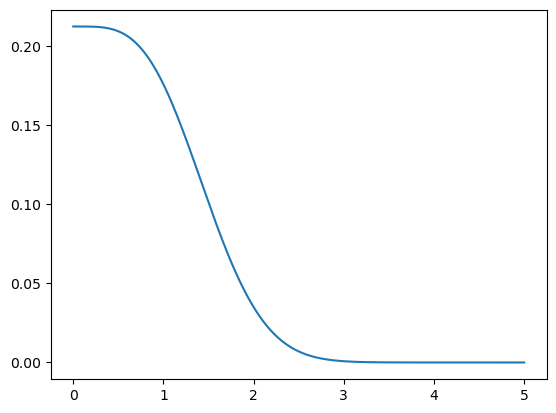

In [ ]:
arr = np.linspace(0,5,1000).reshape((1000,1))
state_in = [[(0,np.sqrt(2/3)),(2,np.sqrt(1/3))]]
# plt.plot(arr,q_pdf((arr[::-1]+1.j*arr)/np.sqrt(2),state_in))
plt.plot(arr,q_pdf(arr,state_in))

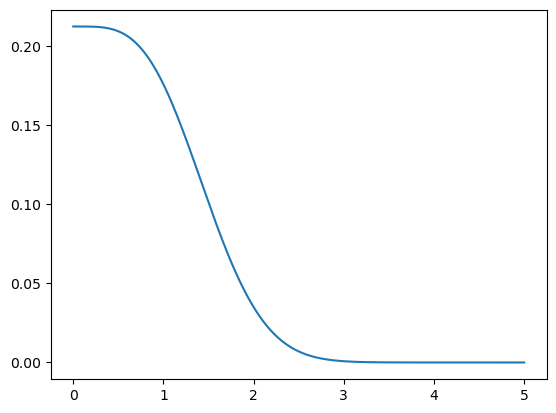

In [ ]:
fun = lambda a: np.exp(-np.abs(a)**2/2)*(np.sqrt(2/3)+a**2/np.sqrt(3)/np.sqrt(factorial(2)) )/np.sqrt(np.pi)

plt.plot(arr,np.abs(fun(arr)**2))

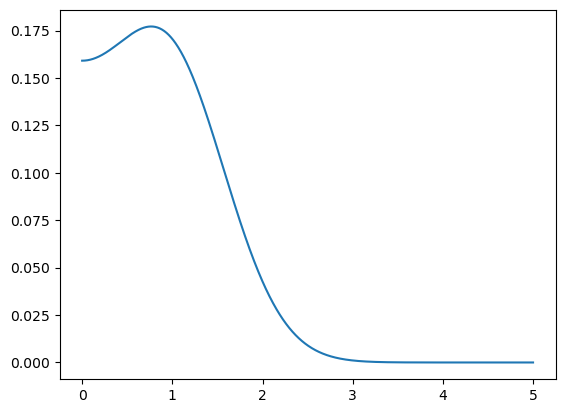

In [ ]:
fun = lambda a: np.exp(-np.abs(a)**2/2)*(np.sqrt(1/2)+a**2/np.sqrt(2)/np.sqrt(factorial(2)) )/np.sqrt(np.pi)

plt.plot(arr,np.abs(fun(arr)**2))

In [ ]:
print(q_pdf([0,1,2,3],state_in))

print(np.abs(fun(np.array([0,1,2,3]))*1.)**2)
print()
for i in [0,1,2,3]:
    print(q_pdf(i,state_in), np.abs(fun(np.array(i))*1.)**2)

[0.31830989 0.34125343 0.08545018 0.00213021]
[0.31830989 0.34125343 0.08545018 0.00213021]

[0.31830989] 0.31830988618379064
[0.34125343] 0.3412534262056614
[0.08545018] 0.08545017743524548
[0.00213021] 0.0021302116396194407


In [ ]:
def q_pdf_b(alpha, state_in):
	# modes = np.asarray(state_in).shape[0]
	# q_modes = np.ones(modes)
	alpha = np.asarray(alpha)
	if(len(alpha.shape)==0):
		alpha = alpha.reshape(1,1)
	elif(len(alpha.shape)==1):
		alpha=alpha.reshape(alpha.shape[0],1)
		
	q_modes=[]
	for i,s in enumerate(state_in):
		num_photons = np.array([ a[0] for a in s],dtype=int)
		amplitudes = np.array([ a[1] for a in s])

		coherent_factor = np.tile(np.exp(-np.abs(alpha[:,i])**2/2),len(num_photons)).reshape(len(num_photons),alpha.shape[0]).T \
								* (np.tile(alpha[:,i],len(num_photons)).reshape(len(num_photons),alpha.shape[0]).T **num_photons )/np.sqrt(factorial(num_photons))
		coherent_factor=coherent_factor.conj()

		scalarprod =  coherent_factor @ amplitudes
		
		q_modes.append(scalarprod/np.pi )
	# np.exp(-np.abs(alpha)**2/2)/np.pi * sum(
	return q_modes

# state1 = [[(0,1)],[(2,1)]]
# state2 = [[(2,1)],[(2,1)]]
# state = [[(0,1),(2,1)],[(2,1)]]

state_in = [[(0, 1), (2, 1)],[(2, 1)]]
print(q_pdf_b([[1,1],[2,2],[3,3]],state_in))

print(q_pdf_b([[1,1],[2,2],[3,3]],[[(0, 1)],[(2, 1)]]) + q_pdf_b([[1,1],[2,2],[3,3]],[[(2, 1)],[(2, 1)]]))# + q_pdf_b([[1,1],[2,2],[3,3]],[[(0, 1)],[(2, 1)]]) + q_pdf_b([[1,1],[2,2],[3,3]],[[(2, 1)],[(2, 1)]]) ) 


[array([0.32958207, 0.16492312, 0.02603973]), array([0.13651736, 0.12184456, 0.02250362])]
[array([0.19306471, 0.04307856, 0.0035361 ]), array([0.13651736, 0.12184456, 0.02250362]), array([0.13651736, 0.12184456, 0.02250362]), array([0.13651736, 0.12184456, 0.02250362])]


In [ ]:
state_in = [[(0,1/np.sqrt(2)),(1,1/np.sqrt(2))],[(0,1/np.sqrt(2)),(1,1/np.sqrt(2))]]

q_pdf_b([[1,1]],[[(0,1/np.sqrt(2)),(1,1/np.sqrt(2))],[(0,1/np.sqrt(2)),(1,1/np.sqrt(2))]])

[array([0.27303472]), array([0.27303472])]

In [ ]:
alpha=np.array([0,1,2,3])

if(len(alpha.shape)==0):
	alpha = alpha.reshape(1,1)
elif(len(alpha.shape)==1):
	alpha=alpha.reshape(alpha.shape[0],1)

	
i=0
num_photons = np.array([ a[0] for a in state_in[0]],dtype=int)
amplitudes = np.array([ a[1] for a in state_in[0]])
print(num_photons,amplitudes)
coherent_factor = np.tile(np.exp(-np.abs(alpha[:,i])**2/2),len(num_photons)).reshape(len(num_photons),alpha.shape[0]).T \
						* (np.tile(alpha[:,i],len(num_photons)).reshape(len(num_photons),alpha.shape[0]).T **num_photons )/np.sqrt(factorial(num_photons))
print(coherent_factor/np.sqrt(np.pi))


coherent_factor=coherent_factor.conj()

scalarprod =  coherent_factor @ amplitudes
# print(scalarprod)
print("res", np.abs(scalarprod)**2/np.pi )

[0 2] [1 1]
[[0.56418958 0.        ]
 [0.34219828 0.24197072]
 [0.07635476 0.21596387]
 [0.00626758 0.03988664]]
res [0.31830989 0.34125343 0.08545018 0.00213021]


In [ ]:
print(np.exp(-np.abs(alpha[:,i])**2/2))
print(np.tile(alpha[:,i],len(num_photons)).reshape(alpha.shape[0],len(num_photons)) **num_photons)

[1.         0.60653066 0.13533528 0.011109  ]
[[1 1]
 [1 9]
 [1 1]
 [1 9]]


In [ ]:
np.tile(alpha[:,i],2).reshape(len(num_photons),alpha.shape[0]).T**num_photons

array([[1, 0],
       [1, 1],
       [1, 4],
       [1, 9]])

In [ ]:
# print(np.tile(np.exp(-np.abs(alpha[:,i])**2/2),len(num_photons)).reshape(alpha.shape[0],len(num_photons)) )
print(fun(alpha))
print()
print(np.tile(np.exp(-np.abs(alpha[:,i])**2/2),len(num_photons)).reshape(alpha.shape[0],len(num_photons)).reshape(alpha.shape[0],len(num_photons)))

print()
print()
np.array([ np.exp(-np.abs(alpha[:,i])**2/2) *alpha[:,i]**0/np.sqrt(factorial(0))/np.sqrt(np.pi) , np.exp(-np.abs(alpha[:,i])**2/2) *alpha[:,i]**2/np.sqrt(factorial(2)) /np.sqrt(np.pi )]).T @ np.array([1,1])



[[0.56418958]
 [0.584169  ]
 [0.29231862]
 [0.04615422]]

[[1.         0.60653066]
 [0.13533528 0.011109  ]
 [1.         0.60653066]
 [0.13533528 0.011109  ]]




array([0.56418958, 0.584169  , 0.29231862, 0.04615422])

In [ ]:
print(np.exp(-np.abs(alpha[:,i])**2/2))

[1.         0.60653066 0.13533528 0.011109  ]


In [ ]:
np.exp(-np.abs(1)**2/2) *1**0/np.sqrt(factorial(0)) + np.exp(-np.abs(1)**2/2) *1**2/np.sqrt(factorial(2))

1.0354126021929868

In [ ]:
a = 1
np.exp(-np.abs(a)**2/2)*(1+a**2/np.sqrt(factorial(2)))

1.0354126021929868

In [ ]:
def q_pdf(alpha, state_in):
	# modes = np.asarray(state_in).shape[0]
	# q_modes = np.ones(modes)
	alpha = np.asarray(alpha)
	if(len(alpha.shape)==0):
		alpha = alpha.reshape(1,1)
	elif(len(alpha.shape)==1):
		alpha=alpha.reshape(alpha.shape[0],1)
		
	q_modes=[]
	for i,s in enumerate(state_in):
		num_photons = np.array([ a[0] for a in s],dtype=int)
		amplitudes = np.array([ a[1] for a in s])

		coherent_factor = np.tile(np.exp(-np.abs(alpha[:,i])**2/2),len(num_photons)).reshape(alpha.shape[0],len(num_photons)) \
								* (np.tile(alpha[:,i],len(num_photons)).reshape(alpha.shape[0],len(num_photons)) **num_photons )/np.sqrt(factorial(num_photons))
		coherent_factor=coherent_factor.conj()

		scalarprod =  coherent_factor @ amplitudes
		
		q_modes.append(np.abs(scalarprod)**2/np.pi )
	# np.exp(-np.abs(alpha)**2/2)/np.pi * sum(
	return np.prod(q_modes,axis=0)

In [ ]:
i = np.argmax(q_pdf(arr,state_in)*np.linspace(0,5,1000))
x = np.linspace(0,5,1000)
x[i]

1.5815815815815815

In [ ]:
break

SyntaxError: 'break' outside loop (668683560.py, line 1)

In [ ]:
unitary = unitary_group.rvs(3)
alpha = np.array([[1]]) # 1,mode
state_in = [[(3,1)]]
print(q_pdf(alpha,state_in))
# print(q_distr(alpha,state_in,cherrypick=True))


[0.01951661]
[0.01951661]


In [ ]:
unitary = unitary_group.rvs(3)
alpha = np.array([[1,2,3],[1,4,2]]) # 3,mode
state_in = [[(3,1)],[(1,1)],[(0,1)]]
print(q_pdf(alpha,state_in))
# print(q_distr(alpha,state_in,cherrypick=True))

[1.78787181e-08 6.52131223e-11]
[1.78787181e-08 6.52131223e-11]


In [ ]:
# alpha.T**(np.array([1,2,5,6]))

In [ ]:

# print(q_distr(alpha,state_repr([3,1,0],photon_cut=6),cherrypick=False,photon_cut=6))
# X_pdf(alpha,state_in,state_in,unitary)

In [ ]:
def sample_q(state_in,size=100):
	q_pdf_bis = lambda alpha: q_pdf(alpha,state_in)

	integ = vegas.Integrator([[-10, 10]])
	result = integ(q_pdf_bis, nitn=30, neval=1e3)
	# print('result = %s    Q = %.2f' % (result, result.Q))
	# integ.map.show_grid(100)
	wgts, p_samples = integ.sample(nbatch=size)
	return p_samples.T, wgts
    


# print(alpha.shape)
state_in  = [[(3,1)]]

alpha,wgt = sample_q(state_in,2000)

print(wgt.shape, wgt)
print(alpha.shape,alpha)

(2817,) [0.13664667 0.13664667 0.13664667 ... 0.0039168  1.11904353 1.11904353]
(2817, 1) [[-6.15988972]
 [-6.45605901]
 [-8.8949595 ]
 ...
 [ 2.97378772]
 [ 3.31473417]
 [ 7.71639673]]


(array([2.19544310e+01, 1.46362873e+01, 5.12270057e+01, 0.00000000e+00,
        2.92725747e+01, 5.85451494e+01, 3.65907184e+01, 3.65907184e+01,
        1.46362873e+01, 7.31814367e+00, 7.31814367e+00, 2.92725747e+01,
        3.65907184e+01, 2.41784630e+04, 8.99068445e+04, 1.74660185e+05,
        1.31564321e+05, 1.95601356e+05, 1.03236271e+05, 1.86727692e+03,
        2.90465299e+03, 8.37251252e+04, 2.28506606e+05, 1.15781673e+05,
        1.73883299e+05, 9.70305864e+04, 1.86385480e+04, 0.00000000e+00,
        8.93620286e-01, 0.00000000e+00, 8.93620286e-01, 0.00000000e+00,
        0.00000000e+00, 8.93620286e-01, 0.00000000e+00, 8.93620286e-01,
        0.00000000e+00, 8.93620286e-01, 0.00000000e+00]),
 array([-10. ,  -9.5,  -9. ,  -8.5,  -8. ,  -7.5,  -7. ,  -6.5,  -6. ,
         -5.5,  -5. ,  -4.5,  -4. ,  -3.5,  -3. ,  -2.5,  -2. ,  -1.5,
         -1. ,  -0.5,   0. ,   0.5,   1. ,   1.5,   2. ,   2.5,   3. ,
          3.5,   4. ,   4.5,   5. ,   5.5,   6. ,   6.5,   7. ,   7.5,
          

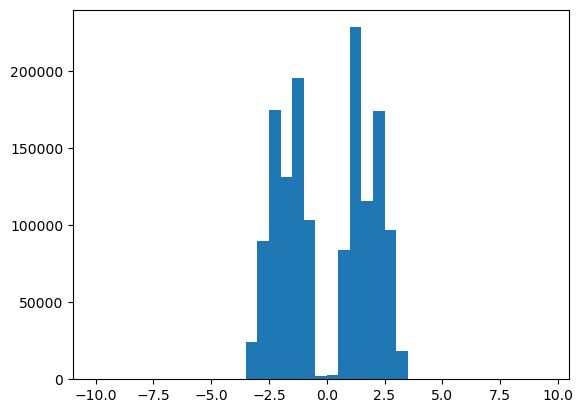

In [ ]:
xbins= np.arange(-10, 10, 0.5)
plt.hist(alpha,bins=xbins, weights=1/wgt)

In [ ]:

size = 10
x = np.linspace(-5,5,100*size)
print(max(q_pdf(x.reshape((100*size,1)),state_in)))
cumulative = np.cumsum(q_pdf(x.reshape((100*size,1)),state_in))
a = np.random.uniform(0,cumulative[-1],size)
print()
# print(cumulative[-1])
res = np.searchsorted(cumulative,a )

x[res]


0.07131159333477746



array([-1.43643644,  1.73673674,  1.61661662, -1.26626627,  1.14614615,
       -1.95695696,  1.21621622, -2.04704705, -1.5965966 ,  1.50650651])

[[(3, 1)]]


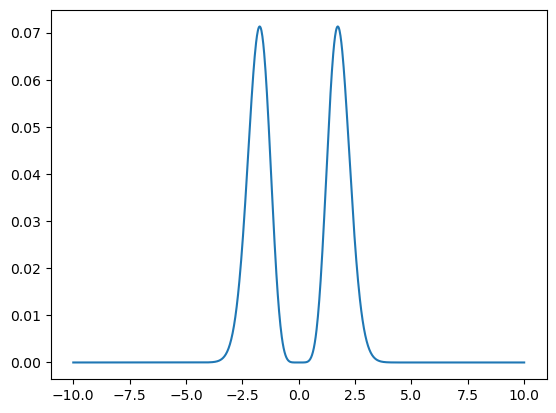

In [ ]:
arr = np.linspace(-10,10,1000).reshape((1000,1))
print(state_in)
plt.plot(arr,q_pdf(arr,state_in))

In [ ]:
x = np.linspace(-10,10,100000)
state_in  = [[(3,1)]]

cumulative = np.cumsum(q_pdf(x.reshape((100000,1)),state_in))
a = np.random.uniform(0,cumulative[-1],100000)
print(a)
# print(cumulative)
res = np.searchsorted(cumulative,a )
print(res)
# a = q_pdf(x[res].reshape((100,1)),state_in)
# a

[183.6353942  763.18780143 202.30253927 ... 209.10964721 711.19425537
 612.29200319]
[40566 60478 40837 ... 40934 59630 58218]


In [ ]:
# cumulative[433]
# x[433]

In [ ]:
# arr = np.linspace(-10,10,1000).reshape((1000,1))
# print(state_in)
# plt.plot(arr,cumulative)

(array([0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00, 1.000e+00,
        2.000e+00, 5.000e+00, 3.000e+00, 1.000e+01, 2.000e+01, 3.500e+01,
        6.200e+01, 9.500e+01, 1.530e+02, 2.200e+02, 3.570e+02, 4.580e+02,
        6.720e+02, 9.330e+02, 1.248e+03, 1.600e+03, 2.094e+03, 2.548e+03,
        2.919e+03, 3.346e+03, 3.646e+0

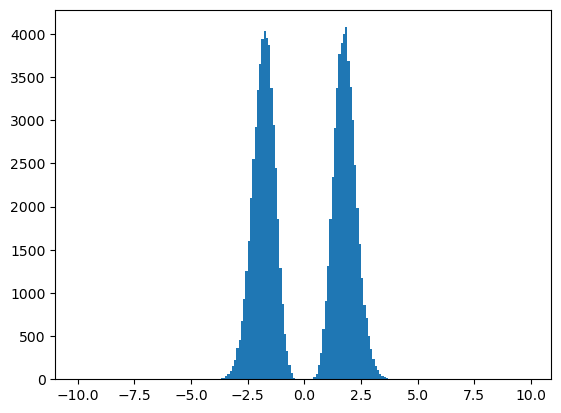

In [ ]:
xbins= np.arange(-10, 10, 0.1)
plt.hist(x[res],bins=xbins)

In [ ]:
# print(result[0].mean())

In [ ]:
# state_in = [[3,0],[1]]
# amps = [[1,1],[1]]

# b = [list(i) for i in zip(*state_in)]
# print(a,b)
# # q_pdf([[1,2]],state_in)

In [ ]:
# def f2(x,y):
#     dx2 = 0
#     # print(y)
#     for d in range(4):
#         dx2 += (x[d] - 1/3.) ** 2
#     ans = math.exp(-dx2 * 100.) * 1013.2167575422921535
#     dx2 = 0
#     for d in range(4):
#         dx2 += (x[d] - 2/3.) ** 2
#     ans += math.exp(-dx2 * 100.) * 1013.2167575422921535
#     return ans / 2.

# f2bis = lambda x: f2(x,2)

# integ = vegas.Integrator(4 * [[0, 1]])


# integ(f2bis, nitn=10, neval=4e4)
# result = integ(f2bis, nitn=30, neval=4e4)
# print('result = %s    Q = %.2f' % (result, result.Q))


In [ ]:
# integ = vegas.Integrator([[0, 10]])

# state_in = [[(3,1)]]

# q_distr_bis= lambda alpha: q_distr(alpha, state_in, cherrypick=True)

# alpha =  np.array([[1],[0.2],[0.3],[2],[1]])
# print(alpha.shape)
# q_distr_bis(alpha)

# alpha =  np.array([1,0.2,0.3,2,1])
# print(len(alpha.shape))
# q_distr_bis(alpha.reshape(5,1))

In [ ]:
# integ(q_distr_bis, nitn=10, neval=4e4)
# result = integ(q_distr_bis, nitn=30, neval=4e4)
# print('result = %s    Q = %.2f' % (result, result.Q))

# integ.map.show_grid(70)

In [ ]:
# q_distr_bis(5)

In [ ]:
# x = np.linspace(0,10,100)[50]
# print(x)
# fx = q_distr_bis(x)
# y = np.empty(x.shape, float)

# map = vegas.AdaptiveMap([[0,10]])
# map.adapt_to_samples(x, q_distr_bis(x), nitn=5) 


# jac = np.empty(x.shape[0], float)

# map.invmap(x, y, jac)
# ysample = (y, jac * fx)


#### CROSS CHECKS

In [ ]:
### q CROSS CHECK
#
modes = 3
# alpha = np.array([[1,2,3],[0.2,0.1,0.1],[0.3,0.1,1],[2 ,3,0.1],[1,2,0.2]])
alpha = np.array([[1,1]])

state_in  = [[(3,1)],[(1,1)]]
# state_in  = [[(3,1)],[(1,1)],[(5,1)]]
print(state_repr([3,1],photon_cut=6))

print(q_distr(alpha,state_repr([3,1,5],photon_cut=6),photon_cut=6))
print()

print(q_distr(alpha,state_in,cherrypick=True))

# alpha = np.array([[1,2,3],[0.2,0.1,0.1],[0.3,0.1,1],[2 ,3,0.1],[1,2,0.2]])

# state_in  = [[(3,1)],[(1,1)],[(5,1)]]

print(q_pdf(alpha,state_in))


[[0. 0. 0. 1. 0. 0.]
 [0. 1. 0. 0. 0. 0.]]
[0.00072746]

[0.00228539]
[0.00228539]


In [ ]:
## SUPERPOSITION CROSS CHECK
# NOT FINISHED


alpha = np.array([[1]])

state_in  = [[(3,1)]]#,[(1,1)],[(5,1)]]

res = [] 
for s in [state_repr([3],photon_cut=6),state_repr([2],photon_cut=6)]:
	res.append(q_distr(alpha,s,photon_cut=6))

print()

# print()
print()
print(q_distr(alpha,state_in,cherrypick=True))





[0.01951661]


In [108]:
def q_pdf_bis(alpha, state_in,verbose=0):
	# modes = np.asarray(state_in).shape[0]
	# q_modes = np.ones(modes)
	if(len(alpha.shape)==0):
		alpha = alpha.reshape(1,1)
	elif(len(alpha.shape)==1):
		alpha=alpha.reshape(alpha.shape[0],1)
	elif(alpha.shape[0]==len(state_in)):
		alpha=alpha.T
		
	q_modes=[]
	for i,s in enumerate(state_in):
		num_photons = np.array([ a[0] for a in s],dtype=int)
		amplitudes = np.array([ a[1] for a in s])

		coherent_factor = np.tile(np.exp(-np.abs(alpha[:,i])**2/2),len(num_photons)).reshape(len(num_photons),alpha.shape[0]).T \
								* (np.tile(alpha[:,i],len(num_photons)).reshape(len(num_photons),alpha.shape[0]).T **num_photons )/np.sqrt(factorial(num_photons))
		coherent_factor=coherent_factor.conj()

		scalarprod =  coherent_factor @ amplitudes

		if(verbose==1):
			print("scalarprod",scalarprod)
		q_modes.append(np.abs(scalarprod)**2/np.pi )
	# np.exp(-np.abs(alpha)**2/2)/np.pi * sum(
	
	return np.array(q_modes)




def X_pdf_bis(alpha,state_in,state_out,unitary):
	if(len(alpha.shape)==0):
		alpha = alpha.reshape(1,1)
	elif(len(alpha.shape)==1):
		alpha=alpha.reshape(alpha.shape[0],1)
	elif(alpha.shape[0]==len(state_in)):
		alpha=alpha.T

	evolved_alpha = np.einsum('ji,lj->li', unitary, alpha)
	# print(evolved_alpha.shape)
	q_modes=[]
	for i,(s,so) in enumerate(list(zip(state_in,state_out))):
		num_photons = np.array([ a[0] for a in s],dtype=int)
		amplitudes = np.array([ a[1] for a in s])

		num_photons_out = np.array([ a[0] for a in so],dtype=int)
		amplitudes_out = np.array([ a[1] for a in so])

		coherent_factor = np.tile(np.exp(-np.abs(alpha[:,i])**2/2),len(num_photons)).reshape(len(num_photons),alpha.shape[0]).T \
								* (np.tile(alpha[:,i],len(num_photons)).reshape(len(num_photons),alpha.shape[0]).T **num_photons )/np.sqrt(factorial(num_photons))
		coherent_factor=coherent_factor.conj()

		evolved_coherent_factor = np.tile(np.exp(-np.abs(evolved_alpha[:,i])**2/2),len(num_photons_out)).reshape(len(num_photons_out),evolved_alpha.shape[0]).T \
								* (np.tile(evolved_alpha[:,i],len(num_photons_out)).reshape(len(num_photons_out),evolved_alpha.shape[0]).T **num_photons_out )/np.sqrt(factorial(num_photons_out))
		
		num = evolved_coherent_factor @ amplitudes_out.conj()
		# print(coherent_factor.shape,amplitudes.shape)
	
		denom = (coherent_factor @ amplitudes).conj()
		# print(num.shape,denom.shape)
		# q_modes.append(num/denom)
		print("x",num,denom)
		q_modes.append(np.divide(num, denom, out=np.zeros_like(num), where=denom!=0))
	# 	print("lol")
	# 	print(num,denom)
	# 	print("lol2", (num/denom))
	# print("lol3",q_modes)
	return np.array(q_modes)

def sample_qmode_bis(state_in,size=1000, method='cumulative'):
	if(method=='cumulative'):	

		x = np.linspace(0,5,100*size+1)
		x = np.array([x.reshape((100*size+1,1))]*len(state_in)).reshape(100*size+1,len(state_in))
		jac = np.abs(x).T
		cumulative = np.cumsum(q_pdf_bis(x,state_in)*jac*2*np.pi,axis=1)/(100*size)
		result=[]
		for i in range(len(state_in)):
			a = np.random.uniform(0,cumulative[i][-1],size)
		# print(cumulative[-1])
			res = np.searchsorted(cumulative[i],a )

			result.append(x[res,i]*np.exp(1.j*np.random.uniform(0,2*np.pi,size=size)))
		return np.array(result)

def approx_bis(state_in,state_out,unitary,size=100000):
	cumul=1
	alphas = np.zeros((size,len(state_in)),dtype=complex)
	# print(alphas.shape)
	# for i,s in enumerate(state_in):
	# 	s = np.array([s])
	# 	# samples_alpha,wgts = sample_qmode(s,size=size)
	# 	samples_alpha = sample_qmode(s,size=size)
	# 	alphas[:,i] = samples_alpha
	np.random.seed(42)
	alphas= sample_qmode_bis(state_in,size=size).T
	# print(alphas.shape)
	return X_pdf_bis(alphas,state_in,state_out,unitary)

def approx_bistest(state_in,state_out,unitary,size=100000):
	cumul=1

	alphas = np.linspace(0,5,100*size+1)
	alphas = np.array([alphas.reshape((100*size+1,1))]*len(state_in)).reshape(100*size+1,len(state_in))
	print(alphas[10])
	return X_pdf_bis(alphas,state_in,state_out,unitary)

In [85]:
unitary = np.array([[np.exp(1.j*np.random.uniform(0,2*np.pi))]])


In [86]:
# unitary = np.array([[np.exp(1.j*np.random.uniform(0,2*np.pi))]])
# print("exact", np.abs(superposition_perm(unitary,[1])[0])**2)
print(expectation_value_permanent(unitary,[2],[2]))



print(np.average(approx_bistest([[(0,1)]],[[(2,1)]],unitary),axis=1)) #NO
print(np.average(approx_bistest([[(2,1)]],[[(2,1)]],unitary),axis=1)) # YES
# print(np.abs(approx([[(2,1)]],[[(2,1)]],unitary))**2)
print()


print(np.average(approx_bistest([[(0,0),(2,1)]],[[(2,1)]],unitary),axis=1)) # YES
print(np.average(approx_bistest([[(0,1),(2,1)]],[[(2,1)]],unitary),axis=1)) # NO
print()
print(np.average(approx_bis([[(0,0),(2,1)]],[[(2,1)]],unitary),axis=1)) # YES
print(np.average(approx_bis([[(0,1),(2,1)]],[[(2,1)]],unitary),axis=1)) # NO

(-0.974509796354422+0.2243449504875535j)
[5.e-06]
[1.00000000e+00 1.00000000e+00 1.00000000e+00 ... 3.72667181e-06
 3.72666249e-06 3.72665317e-06]
[-5.74235433+1.32196536j]
[5.e-06]
[0.00000000e+00 1.76776695e-13 7.07106781e-13 ... 6.58788463e-05
 6.58786947e-05 6.58785432e-05]
[-0.9745097+0.22434493j]

[5.e-06]
[0.00000000e+00 1.76776695e-13 7.07106781e-13 ... 6.58788463e-05
 6.58786947e-05 6.58785432e-05]
[-0.9745097+0.22434493j]
[5.e-06]
[1.00000000e+00 1.00000000e+00 1.00000000e+00 ... 6.96055181e-05
 6.96053572e-05 6.96051964e-05]
[-0.66455353+0.15298895j]

[ 0.2732957 +0.44011012j  0.17908764+0.06313554j -0.11904447-0.38330561j
 ... -0.32327535+0.28715204j -0.17167636+0.46611217j
  0.51650014+0.01012705j]
[-0.9745098+0.22434495j]
[ 0.79777437+0.39331794j  0.33718675+0.09208268j  0.11293664-0.47294021j
 ... -0.07826438+0.34006984j  0.2686425 +0.47820844j
  1.01028145+0.00922916j]
[-0.54381302+0.11751546j]


In [87]:
print(approx_bis([[(0,0),(2,1)]],[[(2,1)]],unitary,size=1))#[10])
print(approx_bis([[(0,1),(2,1)]],[[(2,1)]],unitary,size=1))#[10])

[0.42058091-0.29983909j]
[[-0.9745098+0.22434495j]]
[0.92651387-0.27122158j]
[[-0.4098294+0.25741997j]]


In [88]:
-0.9745098+0.22434495j

(-0.9745098+0.22434495j)

In [109]:
np.random.seed(42)
alpha = sample_qmode_bis([[(0,1),(2,1)]],size=1)#.T


print("alpha", alpha)

print("q_pdf",q_pdf_bis(alpha,[[(0,1),(2,1)]],verbose=1))
print()
print("X_pdf",X_pdf_bis(alpha,[[(0,1),(2,1)]],[[(2,1)]],unitary))



alpha [[1.04767722-0.33521999j]]
scalarprod [0.92651387+0.27122158j]
q_pdf [[0.29666135]]

x [-0.3342638+0.34579551j] [0.92651387-0.27122158j]
X_pdf [[-0.4329313+0.24648869j]]


In [90]:

print(np.average(approx_bis([[(0,1)]],[[(2,1)]],unitary),axis=1))
print(np.average(approx_bis([[(2,1)]],[[(2,1)]],unitary),axis=1))
print("lol",np.average(approx_bis([[(0,1),(2,1)]],[[(2,1)]],unitary),axis=1)-
np.average(approx_bis([[(2,1)]],[[(2,1)]],unitary),axis=1))
print(np.average(approx_bis([[(2,1)]],[[(2,1)]],unitary),axis=1))

[0.79086019-0.j 0.22200387-0.j 0.51769296-0.j ... 0.57056682-0.j
 0.7074974 -0.j 0.7810835 -0.j]
[-0.0013509-0.00057325j]
[ 0.2732957 +0.44011012j  0.17908764+0.06313554j -0.11904447-0.38330561j
 ... -0.32327535+0.28715204j -0.17167636+0.46611217j
  0.51650014+0.01012705j]
[-0.9745098+0.22434495j]
[ 0.79777437+0.39331794j  0.33718675+0.09208268j  0.11293664-0.47294021j
 ... -0.07826438+0.34006984j  0.2686425 +0.47820844j
  1.01028145+0.00922916j]
[ 0.2732957 +0.44011012j  0.17908764+0.06313554j -0.11904447-0.38330561j
 ... -0.32327535+0.28715204j -0.17167636+0.46611217j
  0.51650014+0.01012705j]
lol [0.43069678-0.10682949j]
[ 0.2732957 +0.44011012j  0.17908764+0.06313554j -0.11904447-0.38330561j
 ... -0.32327535+0.28715204j -0.17167636+0.46611217j
  0.51650014+0.01012705j]
[-0.9745098+0.22434495j]


In [91]:

print(np.average(approx_bis([[(2,1)]],[[(0,1)]],unitary),axis=1))
print("lol",np.average(approx_bis([[(2,1)]],[[(0,1),(2,1)]],unitary),axis=1)-
np.average(approx_bis([[(2,1)]],[[(2,1)]],unitary),axis=1))
print(np.average(approx_bis([[(2,1)]],[[(2,1)]],unitary),axis=1))

[ 0.2732957 +0.44011012j  0.17908764+0.06313554j -0.11904447-0.38330561j
 ... -0.32327535+0.28715204j -0.17167636+0.46611217j
  0.51650014+0.01012705j]
[-0.00011836+0.00243602j]
[ 0.2732957 +0.44011012j  0.17908764+0.06313554j -0.11904447-0.38330561j
 ... -0.32327535+0.28715204j -0.17167636+0.46611217j
  0.51650014+0.01012705j]
[ 0.2732957 +0.44011012j  0.17908764+0.06313554j -0.11904447-0.38330561j
 ... -0.32327535+0.28715204j -0.17167636+0.46611217j
  0.51650014+0.01012705j]
lol [-0.00011836+0.00243602j]
[ 0.2732957 +0.44011012j  0.17908764+0.06313554j -0.11904447-0.38330561j
 ... -0.32327535+0.28715204j -0.17167636+0.46611217j
  0.51650014+0.01012705j]
[-0.9745098+0.22434495j]


In [92]:

print("unitary",unitary)
alpha = sample_qmode_bis([[(2,1)]],10)
print(alpha.shape)
alpha = np.asarray(alpha)
if(len(alpha.shape)==0):
	alpha = alpha.reshape(1,1)
elif(len(alpha.shape)==1):
	alpha=alpha.reshape(alpha.shape[0],1)
elif(alpha.shape[0]==1):
	alpha=alpha.T

print(alpha, alpha.shape)
print()
evolved_alpha = np.einsum('ji,lj->li', unitary, alpha)
print(evolved_alpha,evolved_alpha.shape)

unitary [[-0.11289421-0.99360701j]]
(1, 10)
[[ 0.84356647+1.06676877j]
 [ 1.46111861+0.61429424j]
 [ 0.40933182+0.96692681j]
 [-0.8715399 +1.30587833j]
 [ 0.56478925+1.10952157j]
 [-1.31591036+0.32311753j]
 [ 0.72355732-1.43825061j]
 [ 1.03516228-2.01461263j]
 [-0.92627399+1.46705198j]
 [-0.34053633+0.65135244j]] (10, 1)

[[ 0.96471517-0.95860557j]
 [ 0.44541524-1.52112796j]
 [ 0.91453407-0.5158754j ]
 [ 1.39592167+0.71854206j]
 [ 1.03866698-0.68643712j]
 [ 0.4696105 +1.27101966j]
 [-1.51074132-0.55656146j]
 [-2.11859706-0.80110641j]
 [ 1.5622441 +0.75473066j]
 [ 0.68563294+0.26482537j]] (10, 1)


In [93]:
i=0
s =[(0,1),(2,1)]
so =[(2,1)]
num_photons = np.array([ a[0] for a in s],dtype=int)
amplitudes = np.array([ a[1] for a in s])

num_photons_out = np.array([ a[0] for a in so],dtype=int)
amplitudes_out = np.array([ a[1] for a in so])


print(num_photons)
coherent_factor = np.tile(np.exp(-np.abs(alpha[:,i])**2/2),len(num_photons)).reshape(len(num_photons),alpha.shape[0]).T \
								* (np.tile(alpha[:,i],len(num_photons)).reshape(len(num_photons),alpha.shape[0]).T **num_photons )/np.sqrt(factorial(num_photons))
coherent_factor=coherent_factor.conj()

evolved_coherent_factor = np.tile(np.exp(-np.abs(evolved_alpha[:,i])**2/2),len(num_photons_out)).reshape(len(num_photons_out),evolved_alpha.shape[0]).T \
						* (np.tile(evolved_alpha[:,i],len(num_photons_out)).reshape(len(num_photons_out),evolved_alpha.shape[0]).T **num_photons_out )/np.sqrt(factorial(num_photons_out))


[0 2]


In [94]:
size = 1
state_in = [[(0,1),(2,1)]]
x = np.linspace(0,5,100*size+1)
x = np.array([x.reshape((100*size+1,1))]*len(state_in)).reshape(100*size+1,len(state_in))
jac = np.abs(x).T
print(jac.shape)
print(q_pdf_bis(x,state_in)[0].shape)
cumulative = np.cumsum(np.array(q_pdf_bis(x,state_in))*jac*2*np.pi,axis=1)/(100*size)

(1, 101)
(101,)


In [95]:
unitary = unitary_group.rvs(3)
state1 = [[(0,1)],[(1,1)],[(1,1)]]
state2 = [[(1,1)],[(1,1)],[(1,1)]]
state = [[(0,1/np.sqrt(2)),(1,1/np.sqrt(2))],[(1,1)],[(1,1)]]


state_o = [[(1,1)],[(1,1)],[(1,1)]]


In [96]:
# print(np.average(approx_bis(state,state_o,unitary,size=10000),axis=1))
print()
print(np.average(approx_bis(state1,state_o,unitary,size=100000),axis=1))
print(np.average(approx_bis(state2,state_o,unitary,size=100000),axis=1))

print(np.average(approx_bis(state,state_o,unitary,size=100000),axis=1))


[0.93615162-0.j 0.38452182-0.j 0.89667083-0.j ... 0.9882508 -0.j
 0.70827823-0.j 0.91119396-0.j]
[ 0.18880879+0.28568595j  0.49076468+0.33582171j  0.39187123+0.46139445j
 ... -0.27302997-0.14039022j  0.45805303-0.3630181j
 -0.56776317-0.00864314j]
[-0.14624262+0.45880138j -0.20830905-0.0124455j  -0.36443383-0.46342774j
 ... -0.13480254-0.55607486j  0.06407867-0.01830318j
 -0.17244101-0.25398064j]
[-0.00252956-0.00056986j -0.81118706+0.43201679j -0.23768522-0.38952078j]
[-0.50235895-0.279385j   -0.33307221-0.05699167j -0.35612644+0.48350968j
 ...  0.15272362+0.40190667j -0.32052059-0.45962247j
  0.59413502+0.00582406j]
[ 0.18880879+0.28568595j  0.49076468+0.33582171j  0.39187123+0.46139445j
 ... -0.27302997-0.14039022j  0.45805303-0.3630181j
 -0.56776317-0.00864314j]
[-0.14624262+0.45880138j -0.20830905-0.0124455j  -0.36443383-0.46342774j
 ... -0.13480254-0.55607486j  0.06407867-0.01830318j
 -0.17244101-0.25398064j]
[-0.235552  +0.17363494j -0.71296422+0.37942961j -0.14655099-0.2473385

In [97]:
[ 0.00377252-0.0048216j  -0.48799842+0.26618406j  0.08357717-0.61011086j]

SyntaxError: invalid syntax. Perhaps you forgot a comma? (2709864205.py, line 1)

In [ ]:
print(np.average(approx_bistest(state1,state_o,unitary,size=100000),axis=1))
print(np.average(approx_bistest(state2,state_o,unitary,size=100000),axis=1))
print(np.average(approx_bistest(state,state_o,unitary,size=100000),axis=1))

[-3.03404587e+02-1.42164723e+03j  2.46042671e-01-2.54144735e-01j
 -3.45516893e+00-2.88282555e+00j]
[-64.75206052-3.03405377e+02j   0.24604267-2.54144735e-01j
  -3.45516893-2.88282555e+00j]
[-75.37868742-3.53198017e+02j   0.24604267-2.54144735e-01j
  -3.45516893-2.88282555e+00j]


In [ ]:
# x = np.linspace(0,5,100+1)
# x = np.array([x.reshape((100+1,1))]*len(state)).reshape(101,2)
# print(x.shape)

# a =sample_qmode_bis(state).T

# approx(a,state,state)
res = np.average(np.prod(approx_bis(state,state_o,unitary),axis=0))

res2 = np.prod(np.average(approx_bis(state,state_o,unitary),axis=1))

print(res, np.abs(res)**2)
print(res2, np.abs(res2)**2)

(-0.14823663629208014-0.31802801738509634j) 0.1231159201810856
(-0.2583911128290664-0.5751613407337803j) 0.3975765350637231


In [ ]:
for _ in range(20):
	print(np.std(np.abs(np.prod(approx_bis(state2,state_o,unitary),axis=0))**2))

1.434969158019625
1.6514148290582538
1.474668890422742
1.4279963479876845
1.945568884331317
3.9953848873446662
1.3331013004320447
1.6475738614384232
1.7726902515285068
2.172970853426187
1.729413178379199
1.235426083736944
1.6701409586714993
1.72317967090476
1.5872992099087477
1.3027017308807531
1.6647376096977007
1.5628368312594687
1.6573995811776105
1.5485858832934336


In [ ]:

# unitary=1/np.sqrt(2)*np.array([[1,1],[1,-1]],dtype=complex)
# unitary = np.array([[1]])
s = [0,2]#,2,1,0,1,1,0,1,1,0]
state1 = [[(0,1)],[(1,1)]]
state2 = [[(1,1)],[(1,1)]]
state = [[(0,1/np.sqrt(2)),(1,1/np.sqrt(2))],[(1,1)]]


so=[1,1]
# state_o = np.array([(tuple(zip([1,1],np.ones(modes))))])
state_o = [[(1,1)],[(1,1)]]
r = superposition_perm(unitary,[[0,1],[1,1]], so)[0]
print("exact", r,np.abs(r)**2)

print(np.abs(approx(state,state_o,unitary,size=10000))**2)

print(approx(state,state_o,unitary,size=10000))
print(approx(state1,state_o,unitary,size=10000))
print(approx(state2,state_o,unitary,size=10000))
# print(X_pdf([[1,2]],state1,state_o,unitary) + X_pdf([[1,2]],state2,state_o,unitary))
# print(X_pdf([[1,2]],state,state_o,unitary))

lol
exact (-0.4499405483235627+0.8575257292868936j) 0.9377968734147273
0.5820809614877586
(-0.3843377974748776+0.6737640782060291j)
(-0.009037517833784349-0.0032220029737136343j)
(-0.44963581042543266+0.8592732272117983j)
